In [16]:
from market.simulators import simulate_heston, simulate_gbm
import seaborn as sns
import numpy as np
import torch
from matplotlib import pyplot as plt

# Sanity Check on the Simulator

## GBM

Simulated stock shape: torch.Size([100000, 31, 1])
Simulated volatility shape: torch.Size([100000, 31])
If all stocks start with 100: True
Std of final stock price: 5.735689640045166
Mean of final stock price: 99.97303771972656
ATM call price: 2.2728586196899414


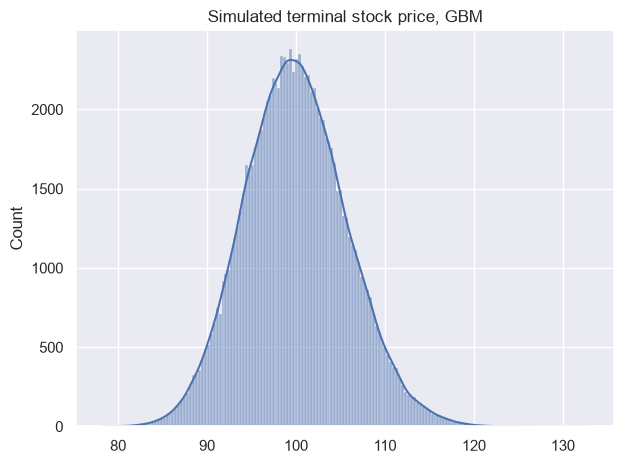

In [18]:
gbm = simulate_gbm(100000)
print(f'Simulated stock shape: {gbm['S'].shape}')
print(f'Simulated volatility shape: {gbm['V'].shape}')
print(f'If all stocks start with 100: {(gbm['S'][:, 0, 0] == 100).sum() == 100000}')
print(f'Std of final stock price: {(gbm['S'][:, -1, 0]).std()}')
print(f'Mean of final stock price: {(gbm['S'][:, -1, 0]).mean()}')
print(f'ATM call price: {(gbm['S'][:, -1, 0] - 100).clamp(min = 0).mean()}')
sns.set_theme()
sns.histplot(data = gbm['S'][:, -1, 0], kde = True)
plt.title("Simulated terminal stock price, GBM")
plt.tight_layout()
plt.show()

## Heston

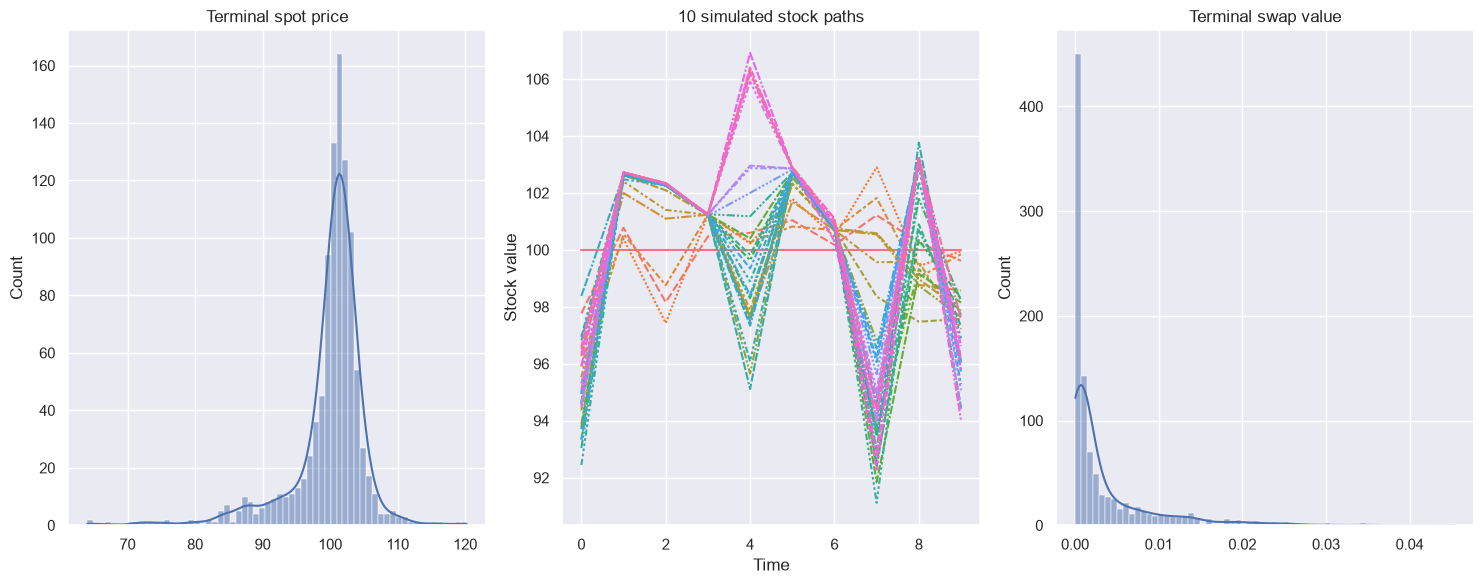

In [ ]:
heston = simulate_heston(1000)
heston.keys()

# heston['S'].shape() = [1000, 31, 2] 
# 2 indicate the number of hedging instrument, i.e. one is stock and one is variance swap

heston['S'][:, :, 0] ## stocks

## terminal prices
sns.set_theme()
fig, ax = plt.subplots(1, 3, figsize = (15, 6))

sns.histplot(data = heston['S'][:, -1, 0].numpy(), ax = ax[0], kde = True)
ax[0].set_title("Terminal spot price")

sns.lineplot(data = heston['S'][:10, :, 0].numpy(), legend = False, ax = ax[1])
ax[1].set_title('10 simulated stock paths')
ax[1].set_ylabel('Stock value')
ax[1].set_xlabel('Time')

sns.histplot(data = heston['S'][:, -1, 1].numpy(), ax = ax[2], kde = True)
ax[2].set_title('Terminal swap value')
plt.tight_layout()
plt.show()

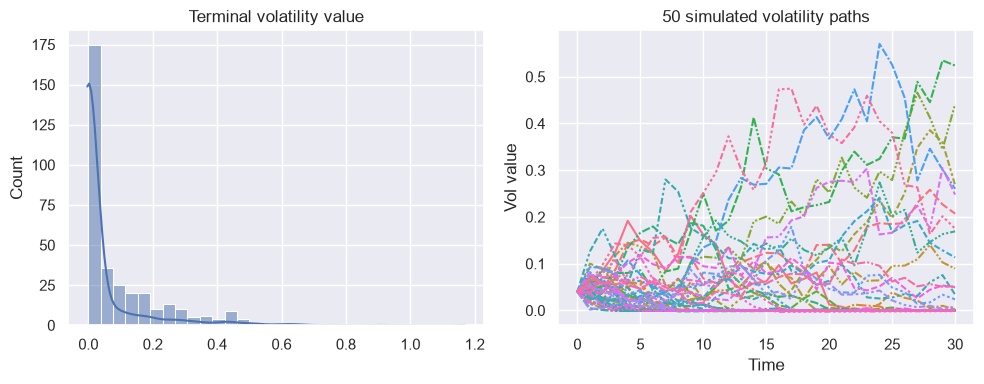

In [53]:
heston['V'] # the hidden volatility path

## terminal prices
sns.set_theme()
fig, ax = plt.subplots(1, 2, figsize = (10, 4))
sns.histplot(data = heston['V'][:, -1].numpy(), ax = ax[0], kde = True, binrange = (0, 0.5))
ax[0].set_title("Terminal volatility value")
sns.lineplot(data = heston['V'][:50, :].numpy().T, legend = False)
ax[1].set_title('50 simulated volatility paths')
ax[1].set_ylabel('Vol value')
ax[1].set_xlabel('Time')
plt.tight_layout()
plt.show()

In [66]:
print(f"Shape of S: {heston['S'].shape}")
print(f"Shape of V: {heston['V'].shape}")
print(f"Mean of terminal stock price: {np.mean(heston['S'][:, -1, 0].numpy())}")

print(f"Count of negative volatility: {np.sum(heston['V'].numpy() < 0)}")
print(f"Count of vol < -0.002: {np.sum(heston['V'].numpy() < -0.002)}")

Shape of S: torch.Size([1000, 31, 2])
Shape of V: torch.Size([1000, 31])
Mean of terminal stock price: 99.99993896484375
Count of negative volatility: 13867
Count of vol < -0.002: 230


# Toy Example of Neural Network

In [74]:
## Learning with numpy, suppose using a+bx+cx^2+dx^3 to approximate sin(x)
x = np.linspace(-np.pi, np.pi, 2000)
y = np.sin(x)

rng = np.random.default_rng(0)
a, b, c, d = rng.normal(size = 4)
learning_rate = 1e-6

# Gradient descent
for t in range(2000):
    y_pred = a + b * x + c * x ** 2 + d * x ** 3

    loss = np.square(y_pred - y).sum()
    if t % 400 == 99:
        print(t, loss)

    ## Gradient descent
    grad_y_pred = 2 * (y_pred - y)
    grad_a = grad_y_pred.sum()
    grad_b = (grad_y_pred * x).sum()
    grad_c = (grad_y_pred * x ** 2).sum()
    grad_d = (grad_y_pred * x ** 3).sum()

    ## Updating
    a -= learning_rate * grad_a
    b -= learning_rate * grad_b
    c -= learning_rate * grad_c
    d -= learning_rate * grad_d

print(f'Result: y = {a} + {b} x + {c} x^2 + {d} x^3')

99 704.3593016451537
499 141.80561551956498
899 34.24523948649255
1299 13.679266905470849
1699 9.746878637823649
Result: y = 0.00046628585139411177 + 0.8408077414722543 x + -8.044206839554327e-05 x^2 + -0.09106404408445065 x^3


In [101]:
## Learning with PyTorch Tensors
import torch
dtype = torch.float
torch.set_default_device('cpu')

x = torch.linspace(-torch.pi, torch.pi, 2000, device = device, dtype = dtype)
y = torch.sin(x)

# Randomly initialize weights
a = torch.randn((), device=device, dtype=dtype)
b = torch.randn((), device=device, dtype=dtype)
c = torch.randn((), device=device, dtype=dtype)
d = torch.randn((), device=device, dtype=dtype)

learning_rate = 1e-6
for t in range(2000):
    # Forward pass: compute predicted y
    y_pred = a + b * x + c * x ** 2 + d * x ** 3

    # Compute and print loss
    loss = (y_pred - y).pow(2).sum().item()
    if t % 200 == 99:
        print(t, loss)

    # Backprop to compute gradients of a, b, c, d with respect to loss
    grad_y_pred = 2.0 * (y_pred - y)
    grad_a = grad_y_pred.sum()
    grad_b = (grad_y_pred * x).sum()
    grad_c = (grad_y_pred * x ** 2).sum()
    grad_d = (grad_y_pred * x ** 3).sum()

    # Update weights using gradient descent
    a -= learning_rate * grad_a
    b -= learning_rate * grad_b
    c -= learning_rate * grad_c
    d -= learning_rate * grad_d


print(f'Result: y = {a.item()} + {b.item()} x + {c.item()} x^2 + {d.item()} x^3')


99 37.0345458984375
299 22.935890197753906
499 15.882342338562012
699 12.352987289428711
899 10.586836814880371
1099 9.702945709228516
1299 9.260555267333984
1499 9.039124488830566
1699 8.928281784057617
1899 8.872795104980469
Result: y = -0.006634676828980446 + 0.857001006603241 x + 0.0011445906711742282 x^2 + -0.09336739778518677 x^3


## Tensor and Autograd

In [78]:
## Find degree 3 polynomial for exp(x)
x = torch.linspace(-1, 1, 1000, dtype = dtype)
y = torch.exp(x)

# Setting requires_grad=True indicates that we want to compute gradients with
# respect to these Tensors during the backward pass.
a = torch.randn((), dtype=dtype, requires_grad=True)
b = torch.randn((), dtype=dtype, requires_grad=True)
c = torch.randn((), dtype=dtype, requires_grad=True)
d = torch.randn((), dtype=dtype, requires_grad=True)

inital_loss = 1
learning_rate = 1e-5
for t in range(5000):
    y_pred = a + b * x + c * x ** 2 + d * x ** 3
    loss = (y_pred - y).pow(2).sum()

    if t % 200 == 99:
        print(f'Iteration t = {t:4d}  loss(t) = {round(loss.item(), 6):10.6f}  a = {a.item():10.6f}  b = {b.item():10.6f}  c = {c.item():10.6f}  d = {d.item():10.6f}')

    # Use autograd to compute the backward pass. This call will compute the
    # gradient of loss with respect to all Tensors with requires_grad=True.
    # After this call a.grad, b.grad. c.grad and d.grad will be Tensors holding
    # the gradient of the loss with respect to a, b, c, d respectively.

    loss.backward()

    # --- autograd ---
    # autograd is PyTorch's automatic differentiation (its implementation of backprop).
    # 1. Forward: every operation involving a tensor with requires_grad=True is recorded
    #    in a computational graph ("what was computed from what").
    # 2. loss.backward(): walks the graph in reverse, applies the chain rule, and stores
    #    dL/dparam in param.grad for every parameter.
    # Gradients ACCUMULATE: each backward() adds to .grad, so .grad must be reset
    # (param.grad = None, or optimizer.zero_grad()) before the next backward().

    # --- with / torch.no_grad() ---
    # `with` runs setup on entering the indented block and undoes it on leaving
    # (even if an error occurs).
    # torch.no_grad() turns off autograd recording inside the block, and turns it back on afterwards.
    #
    # Why the parameter update must be inside no_grad():
    # autograd records ANY operation on requires_grad tensors; it cannot tell
    # "model computation" from "parameter update". If the update were recorded:
    #   - the new parameter would depend on the old one, so backward() would differentiate
    #     through every past update (gradient w.r.t. the INITIAL parameters, not the current ones);
    #   - the graph would grow every step (slower, more memory);
    #   - an in-place update (a -= ...) on a leaf tensor raises a RuntimeError.
    #
    # Use no_grad() for: parameter updates, evaluation on a test set.
    # Never use it in the training forward pass (e.g. the hedging rollout): it would cut the
    # gradient chain, and the parameters would receive no gradient.
    with torch.no_grad():
        a -= learning_rate * a.grad
        b -= learning_rate * b.grad
        c -= learning_rate * c.grad
        d -= learning_rate * d.grad

        a.grad = None
        b.grad = None
        c.grad = None
        d.grad = None

print(f'Result: y = {a.item()} + {b.item()} x + {c.item()} x^2 + {d.item()} x^3')

Iteration t =   99  loss(t) =  59.269039  a =   0.785453  b =   0.837354  c =   0.697468  d =  -0.062967
Iteration t =  299  loss(t) =   3.090126  a =   0.939534  b =   1.021151  c =   0.688664  d =   0.062197
Iteration t =  499  loss(t) =   1.308946  a =   0.956052  b =   1.046851  c =   0.647601  d =   0.086752
Iteration t =  699  loss(t) =   0.747305  a =   0.967040  b =   1.047962  c =   0.617370  d =   0.095215
Iteration t =  899  loss(t) =   0.452423  a =   0.975018  b =   1.045406  c =   0.595385  d =   0.100856
Iteration t = 1099  loss(t) =   0.290226  a =   0.980820  b =   1.042452  c =   0.579398  d =   0.105777
Iteration t = 1299  loss(t) =   0.198769  a =   0.985038  b =   1.039599  c =   0.567774  d =   0.110325
Iteration t = 1499  loss(t) =   0.145420  a =   0.988105  b =   1.036916  c =   0.559322  d =   0.114570
Iteration t = 1699  loss(t) =   0.112841  a =   0.990335  b =   1.034405  c =   0.553176  d =   0.118541
Iteration t = 1899  loss(t) =   0.091790  a =   0.99195

## Use Neural Network

In [ ]:
## getting back to the sin(x) example
x = torch.linspace(-torch.pi, torch.pi, 2000)
y = torch.sin(x)

p = torch.tensor([1,2,3])
xx = x.unsqueeze(-1).pow(p) ## each row is [x, x^2, x^3]

## nn.Sequential stores the structure of the nn
model = torch.nn.Sequential(
    torch.nn.Linear(3, 1),
    torch.nn.Flatten(0,1)
)
loss_fn = torch.nn.MSELoss(reduction = 'sum')
learning_rate = 1e-6

for t in range(2000):
    y_pred = model(xx)
    loss = loss_fn(y_pred, y)
    model.zero_grad() ## emptying all calculated gradient, equivalent to a.grad = None
    loss.backward()
    with torch.no_grad():
        for param in model.parameters():
            param -= learning_rate * param.grad

linear_layer = model[0]
# For linear layer, its parameters are stored as `weight` and `bias`.
print(f'Result: y = {linear_layer.bias.item()} + {linear_layer.weight[:, 0].item()} x + {linear_layer.weight[:, 1].item()} x^2 + {linear_layer.weight[:, 2].item()} x^3')

Result: y = -0.01490429975092411 + 0.8332119584083557 x + 0.0025712396018207073 x^2 + -0.08998361229896545 x^3


## NN with Optim

In [95]:
x = torch.linspace(-torch.pi, torch.pi, 2000)
y = torch.sin(x)

p = torch.tensor([1,2,3])
xx = x.unsqueeze(-1).pow(p) ## each row is [x, x^2, x^3]

## nn.Sequential stores the structure of the nn
model = torch.nn.Sequential(
    torch.nn.Linear(3, 1),
    torch.nn.Flatten(0,1)
)
loss_fn = torch.nn.MSELoss(reduction = 'sum')
optimizer = torch.optim.Adam(model.parameters(), lr = 1e-3)

for t in range(2000):
    y_pred = model(xx)
    loss = loss_fn(y_pred, y)
    if t % 500 == 0:
        print(f'Current loss: {loss}')
    optimizer.zero_grad() ## emptying all calculated gradient, equivalent to a.grad = None
    loss.backward()
    optimizer.step()

linear_layer = model[0]
# For linear layer, its parameters are stored as `weight` and `bias`.
print(f'Result: y = {linear_layer.bias.item()} + {linear_layer.weight[:, 0].item()} x + {linear_layer.weight[:, 1].item()} x^2 + {linear_layer.weight[:, 2].item()} x^3')

Current loss: 72270.84375
Current loss: 3884.23876953125
Current loss: 892.8154296875
Current loss: 743.0900268554688
Result: y = 0.0002077515673590824 + 0.1155887320637703 x + -4.069778515258804e-05 x^2 + 0.014366996474564075 x^3


## Customized NN

In [109]:
class Polynomial3(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.a = torch.nn.Parameter(torch.randn(()))
        self.b = torch.nn.Parameter(torch.randn(()))
        self.c = torch.nn.Parameter(torch.randn(()))
        self.d = torch.nn.Parameter(torch.randn(()))

    def forward(self, x):
        return self.a + self.b * x + self.c * x ** 2 + self.d * x ** 3

    def string(self):
        return f'y = {self.a.item()} + {self.b.item()} x + {self.c.item()} x^2 + {self.d.item()} x^3'

# Create Tensors to hold input and outputs.
x = torch.linspace(-torch.pi, torch.pi, 2000)
y = torch.sin(x)

# Construct our model by instantiating the class defined above
model = Polynomial3()

# Construct our loss function and an Optimizer. The call to model.parameters()
# in the SGD constructor will contain the learnable parameters (defined 
# with torch.nn.Parameter) which are members of the model.
criterion = torch.nn.MSELoss(reduction='sum')
optimizer = torch.optim.SGD(model.parameters(), lr=1e-6)
for t in range(2000):
    # Forward pass: Compute predicted y by passing x to the model
    y_pred = model(x)

    # Compute and print loss
    loss = criterion(y_pred, y)
    if t % 100 == 99:
        print(t, loss.item())

    # Zero gradients, perform a backward pass, and update the weights.
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print(f'Result: {model.string()}')

99 3095.2685546875
199 2157.404296875
299 1505.767822265625
399 1052.5965576171875
499 737.1737060546875
599 517.4456176757812
699 364.2559509277344
799 257.3731689453125
899 182.74378967285156
999 130.5977020263672
1099 94.13639068603516
1199 68.62556457519531
1299 50.76515197753906
1399 38.25341033935547
1499 29.48352813720703
1599 23.333187103271484
1699 19.017648696899414
1799 15.98809814453125
1899 13.860307693481445
1999 12.365204811096191
Result: y = 0.06036237254738808 + 0.8400173187255859 x + -0.010413511656224728 x^2 + -0.09095161408185959 x^3


## Exercise

Current loss: 0.35760632157325745
Current loss: 0.011287915520370007
Current loss: 0.003254773560911417
Current loss: 0.0008446061983704567
Current loss: 0.00023426034022122622
Current loss: 6.0821923398179933e-05
x = -0.50   model = -0.0033   true =  0.00
x =  0.00   model =  0.0167   true =  0.00
x =  0.50   model =  0.4984   true =  0.50
x =  1.00   model =  0.9713   true =  1.00
x =  1.50   model =  1.0012   true =  1.00


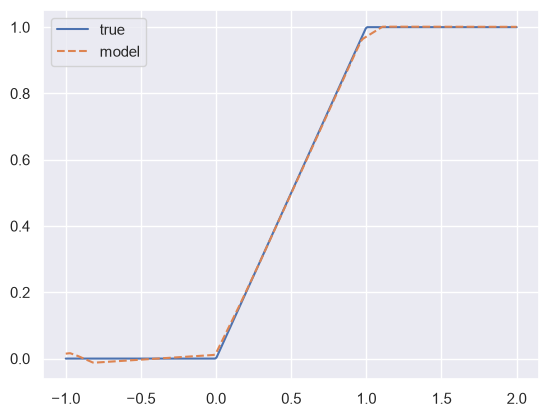

In [104]:
## use the clip function
x = torch.linspace(-5, 5, 2000).unsqueeze(-1)
y = torch.clamp(x, min = 0, max = 1)

model = torch.nn.Sequential(
    torch.nn.Linear(1, 16),
    torch.nn.ReLU(),
    torch.nn.Linear(16, 1)
)

loss_fn = torch.nn.MSELoss(reduction = 'mean')
optimizer = torch.optim.Adam(model.parameters(), lr = 1e-3)

for t in range(3000):
    y_pred = model(x)
    loss = loss_fn(y_pred, y)
    if t % 500 == 0:
        print(f'Current loss: {loss}')
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

x_test = torch.tensor([-0.5, 0, 0.5, 1, 1.5]).unsqueeze(-1)
with torch.no_grad():
    y_hat = model(x_test)
y_true = torch.clamp(x_test, min = 0, max = 1)

for xi, yh, yt in zip(x_test.squeeze(-1), y_hat.squeeze(-1), y_true.squeeze(-1)):
    print(f"x = {xi:5.2f}   model = {yh:7.4f}   true = {yt:5.2f}")


x_plot = torch.linspace(-1, 2, 300).unsqueeze(-1)    # (300, 1)
with torch.no_grad():
    y_plot = model(x_plot)

plt.plot(x_plot.squeeze(-1), x_plot.clamp(0, 1).squeeze(-1), label="true")
plt.plot(x_plot.squeeze(-1), y_plot.squeeze(-1), "--", label="model")
plt.legend()
plt.show()

In [ ]:
## use the clip function
x = torch.linspace(-5, 5, 2000).unsqueeze(-1)
y = torch.clamp(x, min = 0, max = 1)


loss_fn = torch.nn.MSELoss(reduction = 'mean')
## Test on different seeds
for seed in range(5):
    torch.manual_seed(seed)
    model = torch.nn.Sequential(
        torch.nn.Linear(1,2),
        torch.nn.ReLU(),
        torch.nn.Linear(2,1)
    )

    optimizer = torch.optim.Adam(model.parameters(), lr = 1e-3)

    for t in range(3000):
        y_pred = model(x)
        loss = loss_fn(y_pred, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    print(f'Final Loss with seed {seed}: {loss}')

Final Loss with seed 0: 0.0350605733692646
Final Loss with seed 1: 0.04603457823395729
Final Loss with seed 2: 0.029540229588747025
Final Loss with seed 3: 0.0017115657683461905
Final Loss with seed 4: 0.2308439463376999


# Check on model.py

In [122]:
from model import Policy

## testing the customized nn class
test_nn = Policy(d_in = 3, m_out = 1)
test_x = torch.randn((5, 3))
test_output = test_nn(test_x)
print(f'nn output shape: {test_output.shape}') ## shape of the output
print(f'nn parameter count: {sum(p.numel() for p in test_nn.parameters())}')
print(test_nn)



nn output shape: torch.Size([5, 1])
nn parameter count: 4481
Policy(
  (net): Sequential(
    (0): Linear(in_features=3, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


# Check on pricing.py

In [19]:
from market.pricing import bs_price, bs_delta, bs_gamma

print(bs_price(100., 100., 30/365, 0.2))      # ≈ 2.287
print(bs_delta(105., 100., 10/365, 0.2))      # ≈ 0.932

S = torch.tensor(105., dtype=torch.float64); h = 0.01; tau = 10/365
print((bs_price(S+h, 100., tau, 0.2) - bs_price(S-h, 100., tau, 0.2)) / (2*h), bs_delta(S, 100., tau, 0.2))
print((bs_delta(S+h, 100., tau, 0.2) - bs_delta(S-h, 100., tau, 0.2)) / (2*h), bs_gamma(S, 100., tau, 0.2))

print(bs_delta(torch.linspace(90, 110, 5), 100., 10/365, 0.2).shape)   # (5,)

tensor(2.2871)
tensor(0.9319)
tensor(0.9319, dtype=torch.float64) tensor(0.9319, dtype=torch.float64)
tensor(0.0378, dtype=torch.float64) tensor(0.0378, dtype=torch.float64)
torch.Size([5])
